# Exercise 1 — Predicting an unknown endpoint

**Part II · Practical work**

Predict the unknown endpoint $L$ from ten observations. Train four networks in **(a)**, compare their errors in **(b)**, and evaluate fixed endpoints in **(c)**.

Run the cells from top to bottom. The network implementation is adapted from `SLT_Neural_Networks_Epsilon_Loss.ipynb`; departures from the template and optional additions are identified below.

## Shared setup

Prepare the libraries, shared settings and reusable functions. Constants specific to **(a)**, **(b)** and **(c)** stay in their respective sections.

### Libraries and types

Import the numerical and plotting libraries. `FloatArray` specifies floating-point entries, `HiddenLayers` describes the widths of the hidden layers.

In [ ]:
import time
from typing import TypeAlias, cast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.typing import NDArray

FloatArray: TypeAlias = NDArray[np.float64]
HiddenLayers: TypeAlias = tuple[int, ...]


### Shared constants

Use $N=10$ observations per input vector. `DATA_SEED` is the reproducible starting seed taken from the course notebook.

In [2]:
N: int = 10  # Observations per input vector.
DATA_SEED: int = 7  # Base seed from the course notebook.


### Plot appearance

Set font size, figure resolution and grid styling. These choices affect appearance only, not data, training or results.

In [3]:
# matplotlib settings (mainly taken from the example notebooks)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})

print ("Settings configured!")


Settings configured!


### Reproducible sampling

Create the base seed sequence. Each task later derives its own random streams, keeping training and evaluation samples separate and reproducible.

In [4]:
seed_sequence: np.random.SeedSequence = np.random.SeedSequence(DATA_SEED)


### Reusable functions

Define sampling, MSE and the three comparison rules $h_1,h_2,h_3$, together with their theoretical risk formulas. These helpers are reused below.

In [ ]:
def sample_examples(
    m: int, random_generator: np.random.Generator
) -> tuple[FloatArray, FloatArray]:
    """Generate examples for training or testing.

    :param m: Number of complete examples, each containing N observations.
    :param random_generator: random generator for endpoints and observations.
    :return: Sorted inputs of shape (m, N) and endpoint labels of shape (m,).
        Each endpoint is drawn uniformly from [1, 5]. Conditional on that
        endpoint, the N observations are independent uniform draws from [0, L].
    """
    labels: FloatArray = random_generator.uniform(1.0, 5.0, m)
    uniform_samples: FloatArray = random_generator.uniform(size=(m, N))
    endpoints_column: FloatArray = labels.reshape(m, 1)
    inputs: FloatArray = uniform_samples * endpoints_column
    return np.sort(inputs, axis=1), labels


def mse(y: FloatArray, predictions: FloatArray) -> float:
    """Compute the empirical mean squared prediction error.

    :param y: True endpoint labels, shape (m,).
    :param predictions: Predicted endpoints, shape (m,), matching y.
    :return: Average squared prediction error.
    :raises ValueError: If inputs are not one-dimensional, have different
        shapes, or contain no examples.
    """
    if y.ndim != 1 or y.shape != predictions.shape or y.size == 0:
        raise ValueError('Expected non-empty 1D arrays of the same shape.')
    return float(np.mean((y - predictions) ** 2))


def baselines(X: FloatArray) -> dict[str, FloatArray]:
    """Predict endpoints using the three rules specified in Task I.1.

    :param X: Observations of shape (m, N), one example per row;
        sorting is not required. N is the global input size.
    :return: Predictions for h1, h2 and h3, each of shape
        (m,): twice the row mean, the row maximum, and (N + 1) / N
        times the row maximum, respectively.
    """
    maximum: FloatArray = X.max(axis=1)
    return {'h1': 2 * X.mean(axis=1), 'h2': maximum,
            'h3': ((N + 1) / N) * maximum}


# def theoretical_risks(L_squared: float) -> dict[str, float]:
#     """Evaluate the exact population risks derived in Part I.

#     :param L_squared: Squared endpoint L, or its expected squared value.
#     :return: Exact risks for h1, h2 and h3, using the
#         global number N of observations per input vector.
#     """
#     return {'h1': L_squared / (3 * N),
#             'h2': 2 * L_squared / ((N + 1) * (N + 2)),
#             'h3': L_squared / (N * (N + 2))}


## II(a) — Train the four networks

Generate each example as specified in **Task I.2**:

1. Draw $L\sim\mathrm{Uniform}[1,5]$.
2. Given $L$, draw $N=10$ independent observations from $\mathrm{Uniform}[0,L]$.

**Input:** the sorted observations. **Target:** the endpoint $L$.

Use the same $m=10{,}000$ training examples for all four prescribed architectures.

### II(a) — Training settings

Set the required training size and four architectures. Epochs, learning rate and initialization seeds follow the course network notebook; `MAX_WORKERS` controls the added parallel execution.

In [6]:
N_TRAIN: int = 10_000
ARCHITECTURES: list[HiddenLayers] = [(16,), (64,), (32, 32), (64, 64, 32)]

# Common training settings from the course notebook.
EPOCHS: int = 4000
LEARNING_RATE: float = 0.003
INIT_SEEDS: list[int] = [11, 22, 33]
MAX_WORKERS: int = 3

training_stream: np.random.SeedSequence = seed_sequence.spawn(1)[0]


### II(a).1 — Generate training examples

Draw the training data and preview three examples. Each row of `X_train` contains $N=10$ sorted values; the matching entry in `y_train` is its endpoint $L$.

**Shapes:** `X_train`: $(m,N)$ · `y_train`: $(m,)$.

In [7]:
X_train: FloatArray
y_train: FloatArray
X_train, y_train = sample_examples(N_TRAIN, np.random.default_rng(training_stream))

print('Training:', X_train.shape, '| Label range:', y_train.min(), y_train.max())
display(pd.DataFrame(X_train[:3], columns=[f'u{i+1}' for i in range(N)])
        .assign(L=y_train[:3]).round(3))

Training: (10000, 10) | Label range: 1.000001149171522 4.999787752448674


,u1,u2,u3,u4,u5,u6,u7,u8,u9,u10,L
0,0.391,0.881,0.958,1.884,1.983,2.077,2.711,2.874,3.407,4.131,4.191
1,0.114,0.123,0.166,0.182,0.198,0.314,0.492,1.016,1.147,1.190,1.212
2,0.001,0.245,0.499,1.400,1.662,1.703,2.429,2.875,2.897,2.957,3.365


### II(a).2 — Define the network

Define tanh hidden layers and a linear output predicting $L$. This cell creates the network class; it does not train a model.

**Source and adaptation:** Course notebook, Section 5. Its ε-loss subgradient is replaced by the MSE gradient. Training with MSE is our interpretation of the exercise's error criterion. Inputs remain unscaled and outputs unrestricted.

In [8]:
# NumPy network and Adam follow the course template; gradient adapted for MSE.
class Network:
    def __init__(self, hidden: HiddenLayers, seed: int) -> None:
        """Create the layers with random initial weights and zero biases."""
        rng: np.random.Generator = np.random.default_rng(seed)
        sizes: tuple[int, ...] = (N,) + tuple(hidden) + (1,)
        self.W: list[FloatArray] = [rng.normal(size=(a, b)) * np.sqrt(2 / (a + b))
                  for a, b in zip(sizes[:-1], sizes[1:])]
        self.b: list[FloatArray] = [np.zeros((1, b)) for b in sizes[1:]]

    def forward(self, X: FloatArray) -> list[FloatArray]:
        """Pass inputs through the network and return inputs and all layer outputs."""
        activations: list[FloatArray] = [X]
        for j, (W, b) in enumerate(zip(self.W, self.b)):
            z = activations[-1] @ W + b
            activations.append(np.tanh(z) if j < len(self.W) - 1 else z)
        return activations

    def predict(self, X: FloatArray) -> FloatArray:
        """Return one predicted endpoint L per input vector, shape (m,)."""
        return self.forward(X)[-1].ravel()

    def gradients(self, X: FloatArray, y: FloatArray) -> list[FloatArray]:
        """Backpropagate the MSE to compute gradients for all weights and biases."""
        acts: list[FloatArray] = self.forward(X)
        # Adaptation of the course template: derivative of MSE, not ε-loss.
        delta: FloatArray = 2 * (acts[-1] - np.asarray(y).reshape(-1, 1)) / len(X)
        gW: list[FloatArray | None] = [None] * len(self.W)
        gb: list[FloatArray | None] = [None] * len(self.b)
        for j in reversed(range(len(self.W))):
            gW[j] = acts[j].T @ delta
            gb[j] = delta.sum(axis=0, keepdims=True)
            if j > 0:
                delta = (delta @ self.W[j].T) * (1 - acts[j] ** 2)
        # The loop fills every placeholder before returning.
        return cast(list[FloatArray], gW + gb)

    def copy_parameters(self) -> list[FloatArray]:
        """Copy the current weights and biases to save a training checkpoint."""
        return [p.copy() for p in self.W + self.b]

    def set_parameters(self, values: list[FloatArray]) -> None:
        """Restore the weights and biases from a saved parameter list."""
        for param, value in zip(self.W + self.b, values):
            param[:] = value


### II(a).3 — Define the training procedure

Define full-batch Adam training with the configured epoch budget. Each run saves and restores its lowest-training-MSE checkpoint, following the course template with the MSE adaptation above. No training is executed yet.

In [9]:
def architecture_name(hidden: HiddenLayers) -> str:
    """Build a readable architecture label including the input and output layers."""
    return ' → '.join(map(str, (N,) + tuple(hidden) + (1,)))

TrainingResult: TypeAlias = tuple[Network, float, int, FloatArray]

def train(hidden: HiddenLayers, seed: int) -> TrainingResult:
    """Train with full-batch Adam and return the best model, MSE, epoch and history."""
    net: Network = Network(hidden, seed)
    params: list[FloatArray] = net.W + net.b
    moment: list[FloatArray] = [np.zeros_like(p) for p in params]
    variance: list[FloatArray] = [np.zeros_like(p) for p in params]
    best_loss: float = np.inf
    best_parameters: list[FloatArray] | None = None
    best_epoch: int = 0
    history: list[tuple[int, float]] = []
    for epoch in range(1, EPOCHS + 1):
        gradients = net.gradients(X_train, y_train)
        for j, (param, grad) in enumerate(zip(params, gradients)):
            moment[j] = 0.9 * moment[j] + 0.1 * grad
            variance[j] = 0.999 * variance[j] + 0.001 * grad ** 2
            param -= LEARNING_RATE * (moment[j] / (1 - 0.9 ** epoch)) / (
                np.sqrt(variance[j] / (1 - 0.999 ** epoch)) + 1e-8)
        # Retain the best TRAINING iterate. Validation never enters this choice.
        loss = mse(y_train, net.predict(X_train))
        if loss < best_loss:
            best_loss, best_parameters, best_epoch = loss, net.copy_parameters(), epoch
        if epoch == 1 or epoch % 100 == 0 or epoch == EPOCHS:
            history.append((epoch, loss))
    # Positive EPOCHS and finite losses ensure a checkpoint was saved.
    net.set_parameters(cast(list[FloatArray], best_parameters))
    return net, best_loss, best_epoch, np.asarray(history)


### II(a).4 — Train and retain one network per architecture

Train each architecture with three initialization seeds (**12 runs**). Retain the lowest-training-MSE run per architecture; test data are not used for selection.

**Implementation addition:** Unlike the course notebook, `ThreadPoolExecutor` runs up to `MAX_WORKERS` independent fits in parallel.

In [10]:
from concurrent.futures import ThreadPoolExecutor, as_completed

# Parallelize independent runs only; batch size and epoch count are unchanged.
# Set to 1 if memory is limited or the CPU is slow.
models: dict[str, Network] = {}
histories: dict[str, FloatArray] = {}
runs: list[dict[str, str | int | float]] = []
selected_runs: dict[str, dict[str, int]] = {}
trials: dict[tuple[HiddenLayers, int], TrainingResult] = {}
started: float = time.perf_counter()
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    # Run all architecture/seed combinations; submit larger networks first.
    jobs = {pool.submit(train, hidden, seed): (hidden, seed)
            for hidden in reversed(ARCHITECTURES) for seed in INIT_SEEDS}
    for job in as_completed(jobs):
        # Collect each result as soon as its independent training run finishes.
        hidden, seed = jobs[job]
        net, loss, best_epoch, history = job.result()
        trials[(hidden, seed)] = (net, loss, best_epoch, history)
        print(f'{architecture_name(hidden)}, Seed {seed}: Train-MSE {loss:.6f}', flush=True)
for hidden in ARCHITECTURES:
    name = architecture_name(hidden)
    for seed in INIT_SEEDS:
        net, loss, best_epoch, history = trials[(hidden, seed)]
        runs.append({'Model': name, 'Seed': seed, 'Train-MSE': loss,
                     'Best training epoch': best_epoch})
    seed = min(INIT_SEEDS, key=lambda s: trials[(hidden, s)][1])
    # Select by training MSE only; index 1 is the loss in TrainingResult.
    net, loss, best_epoch, history = trials[(hidden, seed)]
    models[name], histories[name] = net, history
    selected_runs[name] = {'Seed': seed, 'Epoch': best_epoch}
print(f'Training time: {(time.perf_counter() - started) / 60:.1f} min')
display(pd.DataFrame(runs).round(6))

10 → 64 → 64 → 32 → 1, Seed 22: Train-MSE 0.081340


10 → 64 → 64 → 32 → 1, Seed 11: Train-MSE 0.081264


10 → 64 → 64 → 32 → 1, Seed 33: Train-MSE 0.081209


10 → 32 → 32 → 1, Seed 22: Train-MSE 0.081487


10 → 32 → 32 → 1, Seed 11: Train-MSE 0.081592


...

10 → 16 → 1, Seed 11: Train-MSE 0.081995


10 → 16 → 1, Seed 22: Train-MSE 0.081993


10 → 16 → 1, Seed 33: Train-MSE 0.081961


Training time: 6.2 min


,Model,Seed,Train-MSE,Best training epoch
0,10 → 16 → 1,11,0.081995,4000
1,10 → 16 → 1,22,0.081993,4000
2,10 → 16 → 1,33,0.081961,4000
3,10 → 64 → 1,11,0.081731,4000
4,10 → 64 → 1,22,0.081637,4000
5,10 → 64 → 1,33,0.081791,4000
6,10 → 32 → 32 → 1,11,0.081592,4000
7,10 → 32 → 32 → 1,22,0.081487,4000
8,10 → 32 → 32 → 1,33,0.081573,4000
9,10 → 64 → 64 → 32 → 1,11,0.081264,4000


## II(b) — Compare training and test errors

Evaluate the four fitted networks and $h_1,h_2,h_3$ on shared training and test data. Present one table and one plot; do not retrain the networks.

**Theory from I.2(b):** … *(to be added later).*

### II(b) — Test settings and theory placeholders

Set the required 20,000 test examples and a separate sampling seed. 

**TODO:** Replace the `None` values with risks from I.2(b) when ready!

In [11]:
N_TEST: int = 20_000
test_stream: np.random.SeedSequence = seed_sequence.spawn(1)[0]

# Replace None with population risks from I.2(b) if finished.
theory: dict[str, float | None] = {
    'h1': None,
    'h2': None,
    'h3': None,
}

### II(b).1 — Generate independent test examples

Draw 20,000 new examples from Task I.2 using the test seed. All seven rules receive this same test set, which was not used for fitting or initialization selection.

In [12]:
X_test: FloatArray
y_test: FloatArray
X_test, y_test = sample_examples(N_TEST, np.random.default_rng(test_stream))

### II(b).2 — Table of prediction errors

Compute training MSE and test MSE for all seven rules. Include theoretical risks where provided; `NaN` means unavailable. The fitted networks remain unchanged.

**Optional addition:** Test standard errors estimate test-sample uncertainty for fixed models, assuming independent examples and finite loss variance. They exclude training variability. The same interpretation is not valid on data already used for fitting.

In [13]:
train_predictions: dict[str, FloatArray] = {name: net.predict(X_train) for name, net in models.items()}
test_predictions: dict[str, FloatArray] = {name: net.predict(X_test) for name, net in models.items()}
train_predictions.update(baselines(X_train))
test_predictions.update(baselines(X_test))
rows: list[dict[str, str | float | np.float64]] = []
for name in train_predictions:
    losses = (test_predictions[name] - y_test) ** 2
    theory_value = theory.get(name)
    rows.append({'Model': name, 'Train-MSE': mse(y_train, train_predictions[name]),
                 'Test-MSE': losses.mean(), 'Test-SE': losses.std(ddof=1) / np.sqrt(N_TEST),
                 'Theory': theory_value if theory_value is not None else np.nan})
comparison: pd.DataFrame = pd.DataFrame(rows).set_index('Model')
display(comparison.round(6))

,Train-MSE,Test-MSE,Test-SE,Theory
Model,,,,
10 → 16 → 1,0.081961,0.079010,0.001578,NaN
10 → 64 → 1,0.081637,0.078817,0.001571,NaN
10 → 32 → 32 → 1,0.081487,0.078654,0.001570,NaN
10 → 64 → 64 → 32 → 1,0.081209,0.078639,0.001569,NaN
h1,0.355208,0.344141,0.004358,NaN
h2,0.164297,0.158839,0.002627,NaN
h3,0.092485,0.088228,0.001714,NaN


### II(b).3 — Plot training and test MSE

Show both MSE values side by side for each rule. Dashed lines mark any theoretical risks entered above.

**Optional addition:** Error bars show ±2 test standard errors, not guaranteed confidence bounds.

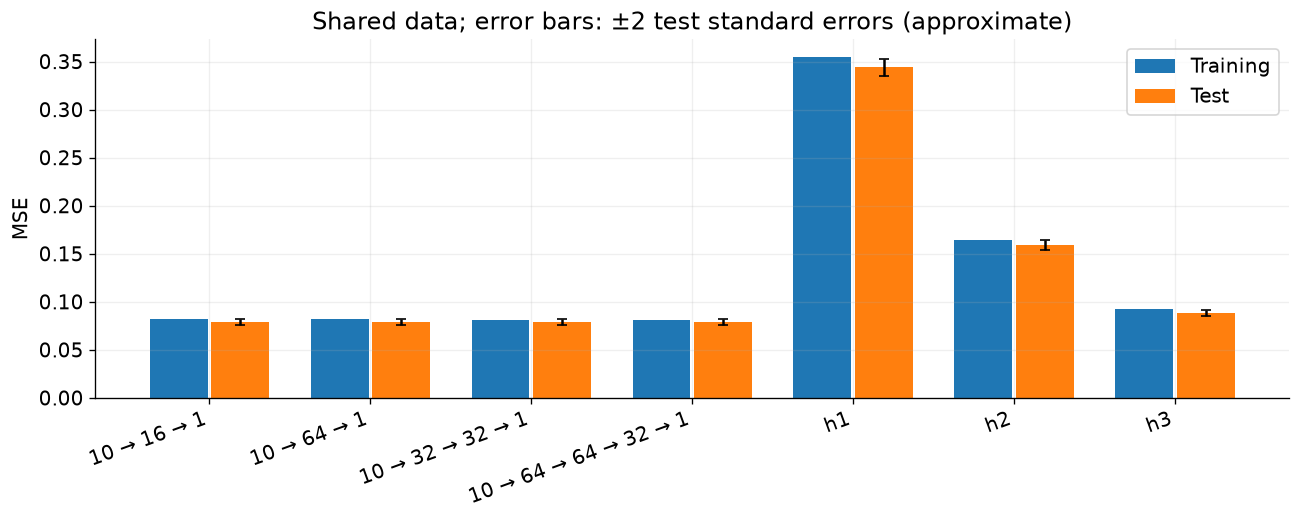

In [14]:
fig, ax = plt.subplots(figsize=(11, 4.5))
positions = np.arange(len(comparison))
ax.bar(positions - 0.19, comparison['Train-MSE'], width=0.36, label='Training')
ax.bar(positions + 0.19, comparison['Test-MSE'], width=0.36, label='Test',
       yerr=2 * comparison['Test-SE'], capsize=3)
for i, name in enumerate(comparison.index):
    theory_value = theory.get(name)
    if theory_value is not None:
        ax.plot([i - 0.35, i + 0.35], [theory_value] * 2, color='black',
                linestyle='--', label=f'{name}: theory')
ax.set_xticks(positions, comparison.index, rotation=20, ha='right')
ax.set(ylabel='MSE', title='Shared data; error bars: ±2 test standard errors (approximate)')
ax.legend()
plt.tight_layout()
plt.show()

### II(b).4 — Notes on reading the comparison

Lower MSE indicates more accurate estimates of the endpoint $L$. In this run, the four networks achieve similar test errors, all lower than those of the comparison rules; $h_3$ performs best among $h_1,h_2,h_3$.

## II(c) — Evaluate fixed endpoints

For each $L\in\{0.5,1,2,3,4,5,6,8\}$, evaluate all seven rules on 5,000 fresh input vectors. Keep the trained networks unchanged and plot empirical MSE against $L$.

### II(c) — Fixed-endpoint settings

Set the prescribed endpoints and 5,000 examples per endpoint. Prepare a separate random stream for each experiment.

In [15]:
N_FIXED: int = 5_000
L_VALUES: FloatArray = np.array([0.5, 1, 2, 3, 4, 5, 6, 8])
fixed_streams: list[np.random.SeedSequence] = seed_sequence.spawn(len(L_VALUES))


### II(c).1 — Define sampling at a fixed $L$

Define a sampler that draws $N=10$ independent observations from $[0,L]$ and sorts them. Unlike Task I.2, $L$ is not drawn anew: every example in this experiment has the same label.

In [16]:
def sample_fixed_endpoint(
    m: int, random_generator: np.random.Generator, fixed_L: float
) -> tuple[FloatArray, FloatArray]:
    """Generate fresh observation vectors for a fixed endpoint in Task II(c).

    :param m: Number of complete examples, each containing N observations.
    :param random_generator: Random generator for the observations.
    :param fixed_L: Positive endpoint shared by all examples.
    :return: Sorted inputs of shape (m, N) and labels of shape (m,),
        all equal to fixed_L. Each observation is drawn uniformly from [0, fixed_L].
    """
    labels: FloatArray = np.full(m, fixed_L, dtype=float)
    inputs: FloatArray = random_generator.uniform(size=(m, N)) * labels[:, None]
    return np.sort(inputs, axis=1), labels


### II(c).2 — Compute errors at each $L$

Generate the fresh vectors, apply all seven unchanged rules and compute empirical MSE. Each endpoint uses a common sample for all rules.

**Optional addition:** Display the empirical errors as a table.

In [17]:
fixed_rows: list[dict[str, str | float | np.float64]] = []
X_fixed: FloatArray
y_fixed: FloatArray
for L, stream in zip(L_VALUES, fixed_streams):
    X_fixed, y_fixed = sample_fixed_endpoint(N_FIXED, np.random.default_rng(stream), fixed_L=L)
    predictions: dict[str, FloatArray] = {name: net.predict(X_fixed) for name, net in models.items()}
    predictions.update(baselines(X_fixed))
    for name, pred in predictions.items():
        losses = (pred - y_fixed) ** 2
        fixed_rows.append({'L': L, 'Model': name, 'MSE': losses.mean(),
                           'SE': losses.std(ddof=1) / np.sqrt(N_FIXED)})
fixed_results: pd.DataFrame = pd.DataFrame(fixed_rows)
fixed_table: pd.DataFrame = fixed_results.pivot(index='L', columns='Model', values='MSE')
display(fixed_table.round(5))



Model,10 → 16 → 1,10 → 32 → 32 → 1,10 → 64 → 1,10 → 64 → 64 → 32 → 1,h1,h2,h3
L,,,,,,,
0.5,0.00352,0.05739,0.02193,0.18441,0.00815,0.00368,0.00203
1.0,0.01091,0.01282,0.01196,0.01334,0.03270,0.01471,0.00811
2.0,0.03735,0.03737,0.03762,0.03835,0.12936,0.06107,0.03380
3.0,0.08339,0.08544,0.08511,0.08380,0.30599,0.14516,0.07974
4.0,0.10877,0.10526,0.10402,0.10803,0.52086,0.24425,0.13336
5.0,0.19267,0.19120,0.19060,0.19085,0.82332,0.38426,0.21063
6.0,0.79682,0.69028,0.60290,0.79716,1.20417,0.55667,0.30536
8.0,5.53145,4.75515,3.77318,5.85162,2.12648,0.94447,0.52101


### II(c).3 — Plot empirical MSE against $L$

Each curve represents one rule. The horizontal axis is $L$; the vertical axis is empirical MSE. Shading marks the training range $[1,5]$.

**Optional addition:** The second panel shows the same empirical errors on a logarithmic MSE axis.

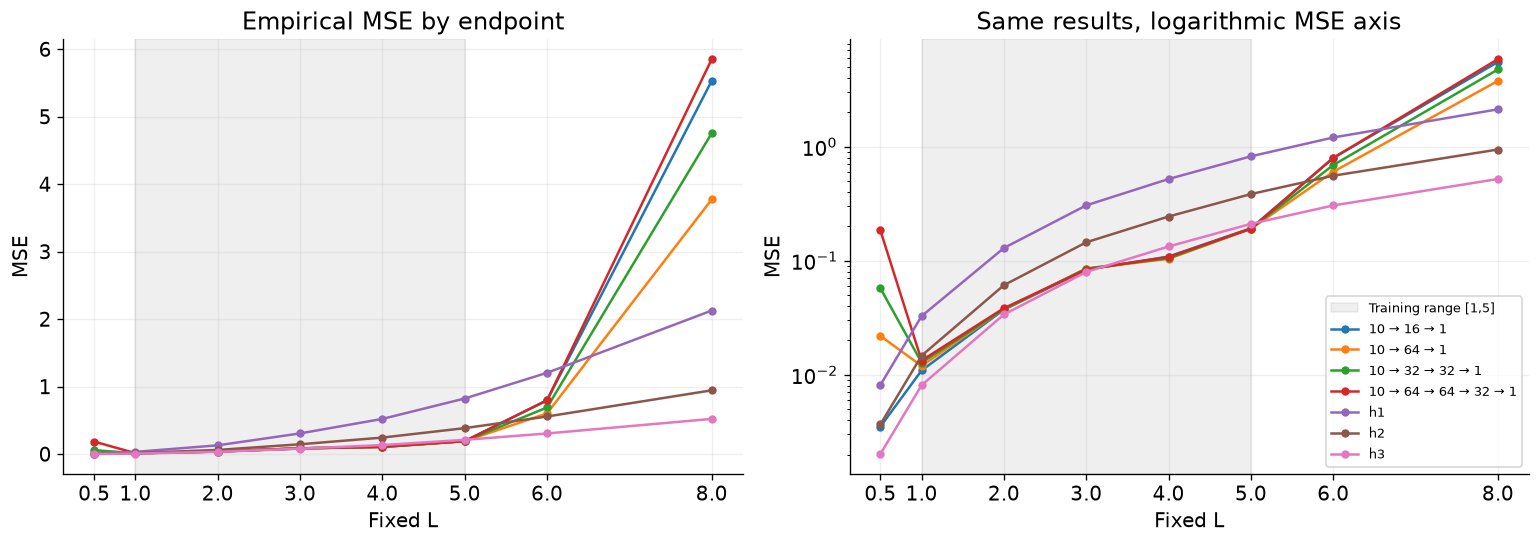

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
for ax in axes:
    ax.axvspan(1, 5, color='grey', alpha=0.12, label='Training range [1,5]')
    for name in comparison.index:
        data = fixed_results[fixed_results.Model == name]
        ax.plot(data.L, data.MSE, 'o-', label=name, markersize=4)
    ax.set(xlabel='Fixed L', ylabel='MSE', xticks=L_VALUES)
axes[0].set_title('Empirical MSE by endpoint')
axes[1].set_yscale('log')
axes[1].set_title('Same results, logarithmic MSE axis')
axes[1].legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()
